# Player Clustering

## Objective

Identify groups of football players with similar statistical profiles
using unsupervised machine learning.

## Methodology

K-Means clustering will be applied separately to defenders, midfielders
and forwards using their seven engineered attribute scores.

The resulting clusters will help identify different statistical
playing-style profiles within each position group.

## Clustering Features

- Finishing
- Creativity
- Passing
- Progression
- Defending
- Ball Security
- Aerial Ability

In [17]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROJECT_ROOT = Path("..")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "players_engineered.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Position distribution:")
print(df["Pos"].value_counts())

Dataset shape: (1692, 109)
Position distribution:
Pos
DF    702
MF    564
FW    426
Name: count, dtype: int64


In [18]:
CLUSTERING_FEATURES = [
    "Finishing_Score",
    "Creativity_Score",
    "Passing_Score",
    "Progression_Score",
    "Defending_Score",
    "BallSecurity_Score",
    "Aerial_Score"
]

# Check feature availability
missing_features = [
    col for col in CLUSTERING_FEATURES
    if col not in df.columns
]

print("Missing features:", missing_features)

# Check missing values
print("\nMissing values:")
print(df[CLUSTERING_FEATURES].isnull().sum())

# Check position groups
print("\nPosition groups:", sorted(df["Pos"].unique()))

Missing features: []

Missing values:
Finishing_Score       0
Creativity_Score      0
Passing_Score         0
Progression_Score     0
Defending_Score       0
BallSecurity_Score    0
Aerial_Score          0
dtype: int64

Position groups: ['DF', 'FW', 'MF']


In [19]:
# Create a separate scaled dataset
df_cluster_scaled = df.copy()

# Store one scaler per position
cluster_scalers = {}

for position in sorted(df["Pos"].unique()):

    position_mask = df["Pos"] == position

    scaler = StandardScaler()

    df_cluster_scaled.loc[position_mask, CLUSTERING_FEATURES] = (
        scaler.fit_transform(
            df.loc[position_mask, CLUSTERING_FEATURES]
        )
    )

    cluster_scalers[position] = scaler

print("Position-wise scaling completed.")

# Validate scaling
for position in sorted(df["Pos"].unique()):

    position_data = df_cluster_scaled.loc[
        df_cluster_scaled["Pos"] == position,
        CLUSTERING_FEATURES
    ]

    print(f"\n{position}")
    print("Mean:", position_data.mean().round(3).tolist())
    print("Std:", position_data.std().round(3).tolist())

Position-wise scaling completed.

DF
Mean: [0.0, 0.0, -0.0, -0.0, -0.0, -0.0, -0.0]
Std: [1.001, 1.001, 1.001, 1.001, 1.001, 1.001, 1.001]

FW
Mean: [0.0, -0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Std: [1.001, 1.001, 1.001, 1.001, 1.001, 1.001, 1.001]

MF
Mean: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Std: [1.001, 1.001, 1.001, 1.001, 1.001, 1.001, 1.001]


In [20]:
import matplotlib.pyplot as plt

position_data = {}

for position in sorted(df["Pos"].unique()):

    position_data[position] = df_cluster_scaled.loc[
        df_cluster_scaled["Pos"] == position,
        CLUSTERING_FEATURES
    ].copy()

k_results = {}

for position, data in position_data.items():

    inertias = []
    silhouette_scores = []
    k_values = range(2, 11)

    for k in k_values:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(data)

        inertias.append(kmeans.inertia_)
        silhouette_scores.append(
            silhouette_score(data, labels)
        )

    k_results[position] = {
        "k_values": list(k_values),
        "inertias": inertias,
        "silhouette_scores": silhouette_scores
    }

print("Cluster evaluation completed.")

Cluster evaluation completed.


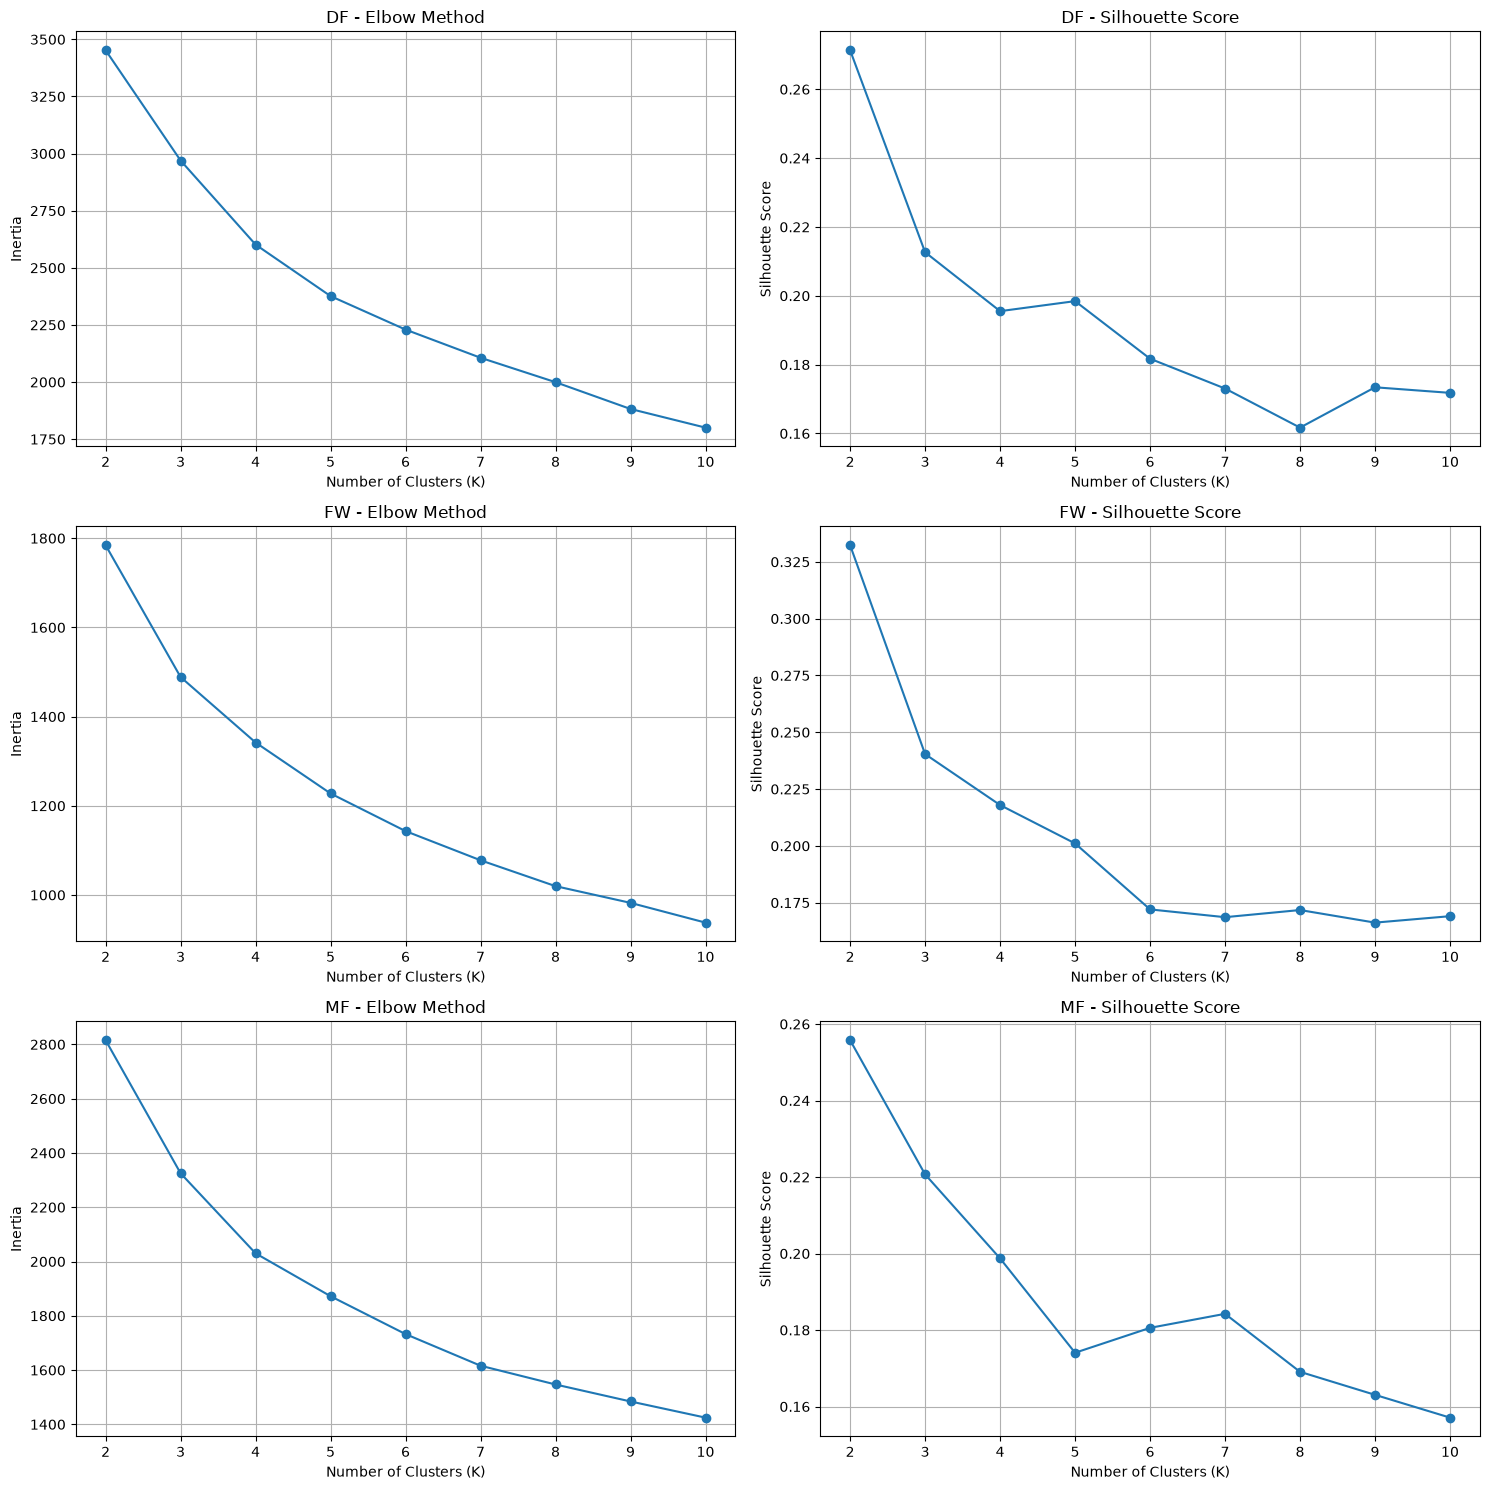

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for i, position in enumerate(sorted(k_results.keys())):

    results = k_results[position]
    k_values = results["k_values"]

    # Elbow Method
    axes[i, 0].plot(
        k_values,
        results["inertias"],
        marker="o"
    )
    axes[i, 0].set_title(f"{position} - Elbow Method")
    axes[i, 0].set_xlabel("Number of Clusters (K)")
    axes[i, 0].set_ylabel("Inertia")
    axes[i, 0].set_xticks(k_values)
    axes[i, 0].grid(True)

    # Silhouette Score
    axes[i, 1].plot(
        k_values,
        results["silhouette_scores"],
        marker="o"
    )
    axes[i, 1].set_title(f"{position} - Silhouette Score")
    axes[i, 1].set_xlabel("Number of Clusters (K)")
    axes[i, 1].set_ylabel("Silhouette Score")
    axes[i, 1].set_xticks(k_values)
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

In [22]:
for position, results in k_results.items():

    print(f"\n{'='*35}")
    print(f"{position} - Cluster Evaluation")
    print(f"{'='*35}")

    evaluation_df = pd.DataFrame({
        "K": results["k_values"],
        "Inertia": results["inertias"],
        "Silhouette Score": results["silhouette_scores"]
    })

    print(evaluation_df.round(4).to_string(index=False))


DF - Cluster Evaluation
 K   Inertia  Silhouette Score
 2 3452.5637            0.2713
 3 2969.6240            0.2127
 4 2601.6814            0.1955
 5 2376.1559            0.1984
 6 2229.6290            0.1817
 7 2106.2847            0.1731
 8 1999.4106            0.1617
 9 1882.1055            0.1734
10 1800.4760            0.1718

FW - Cluster Evaluation
 K   Inertia  Silhouette Score
 2 1784.4059            0.3323
 3 1488.7141            0.2404
 4 1341.9548            0.2180
 5 1227.6445            0.2011
 6 1143.2748            0.1720
 7 1077.8382            0.1686
 8 1019.8395            0.1718
 9  982.3324            0.1662
10  938.0248            0.1690

MF - Cluster Evaluation
 K   Inertia  Silhouette Score
 2 2815.3897            0.2558
 3 2325.0748            0.2207
 4 2030.0844            0.1987
 5 1872.1041            0.1741
 6 1732.5563            0.1806
 7 1616.0665            0.1842
 8 1546.8633            0.1691
 9 1484.3329            0.1631
10 1424.7866            0.

In [23]:
cluster_comparison = {}

for position, data in position_data.items():

    print(f"\n{'='*35}")
    print(f"{position} - Cluster Size Comparison")
    print(f"{'='*35}")

    for k in [2, 4]:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(data)

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        cluster_comparison[(position, k)] = {
            "model": model,
            "labels": labels,
            "sizes": cluster_sizes
        }

        print(f"\nK = {k}")
        print(cluster_sizes.to_string())


DF - Cluster Size Comparison

K = 2
0    328
1    374

K = 4
0    131
1    177
2    197
3    197

FW - Cluster Size Comparison

K = 2
0    220
1    206

K = 4
0    118
1     94
2     86
3    128

MF - Cluster Size Comparison

K = 2
0    316
1    248

K = 4
0    166
1    108
2    166
3    124


In [24]:
for position in sorted(df["Pos"].unique()):

    print(f"\n{position}")

    for k in [2, 4]:

        sizes = cluster_comparison[(position, k)]["sizes"]

        print(f"K={k}: {sizes.to_dict()}")


DF
K=2: {0: 328, 1: 374}
K=4: {0: 131, 1: 177, 2: 197, 3: 197}

FW
K=2: {0: 220, 1: 206}
K=4: {0: 118, 1: 94, 2: 86, 3: 128}

MF
K=2: {0: 316, 1: 248}
K=4: {0: 166, 1: 108, 2: 166, 3: 124}


In [25]:
for position in sorted(df["Pos"].unique()):

    print(f"\n{'='*60}")
    print(f"{position} - CLUSTER PROFILES")
    print(f"{'='*60}")

    for k in [2, 4]:

        result = cluster_comparison[(position, k)]

        profile_df = df.loc[
            position_data[position].index,
            CLUSTERING_FEATURES
        ].copy()

        profile_df["Cluster"] = result["labels"]

        cluster_profiles = profile_df.groupby("Cluster").mean()

        print(f"\nK = {k}")
        print(cluster_profiles.round(2).to_string())


DF - CLUSTER PROFILES

K = 2
         Finishing_Score  Creativity_Score  Passing_Score  Progression_Score  Defending_Score  BallSecurity_Score  Aerial_Score
Cluster                                                                                                                        
0                  53.72             68.87          50.04              63.44            50.56               32.74         28.38
1                  46.71             33.58          50.10              38.34            49.64               65.27         69.09

K = 4
         Finishing_Score  Creativity_Score  Passing_Score  Progression_Score  Defending_Score  BallSecurity_Score  Aerial_Score
Cluster                                                                                                                        
0                  64.77             81.37          62.24              73.90            46.47               38.74         24.85
1                  48.21             42.43          64.40          

In [26]:
for position in ["FW", "MF"]:

    print(f"\n{'='*60}")
    print(f"{position} - CLUSTER PROFILES")
    print(f"{'='*60}")

    for k in [2, 4]:

        result = cluster_comparison[(position, k)]

        profile_df = df.loc[
            position_data[position].index,
            CLUSTERING_FEATURES
        ].copy()

        profile_df["Cluster"] = result["labels"]

        print(f"\nK = {k}")

        display(
            profile_df.groupby("Cluster")
            .mean()
            .round(2)
        )


FW - CLUSTER PROFILES

K = 2


,Finishing_Score,Creativity_Score,Passing_Score,Progression_Score,Defending_Score,BallSecurity_Score,Aerial_Score
Cluster,,,,,,,
0,45.19,65.25,66.04,68.77,60.03,59.56,29.94
1,55.38,33.96,33.11,30.20,39.53,40.03,71.67



K = 4


,Finishing_Score,Creativity_Score,Passing_Score,Progression_Score,Defending_Score,BallSecurity_Score,Aerial_Score
Cluster,,,,,,,
0,58.78,27.61,25.90,22.47,32.29,36.94,80.07
1,29.73,43.47,47.73,53.01,69.89,43.65,44.02
2,63.92,53.63,50.84,44.65,41.41,51.71,56.53
3,47.83,73.39,73.71,77.15,57.88,65.95,22.68



MF - CLUSTER PROFILES

K = 2


,Finishing_Score,Creativity_Score,Passing_Score,Progression_Score,Defending_Score,BallSecurity_Score,Aerial_Score
Cluster,,,,,,,
0,35.86,34.49,45.74,38.64,59.95,56.26,59.23
1,68.22,69.97,55.63,64.68,37.53,42.23,38.44



K = 4


,Finishing_Score,Creativity_Score,Passing_Score,Progression_Score,Defending_Score,BallSecurity_Score,Aerial_Score
Cluster,,,,,,,
0,30.71,25.78,39.07,31.10,63.80,55.50,62.44
1,63.64,50.74,30.36,46.25,36.22,26.60,60.74
2,42.93,52.77,66.07,54.71,58.36,67.55,46.52
3,73.81,78.47,60.63,72.67,32.74,39.92,29.05


In [27]:
FINAL_K = 4

df_clustered = df.copy()

final_cluster_models = {}

for position in sorted(df["Pos"].unique()):

    position_mask = df["Pos"] == position

    X = df_cluster_scaled.loc[
        position_mask,
        CLUSTERING_FEATURES
    ]

    kmeans = KMeans(
        n_clusters=FINAL_K,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    df_clustered.loc[position_mask, "PlayingStyle_Cluster"] = labels

    final_cluster_models[position] = kmeans

df_clustered["PlayingStyle_Cluster"] = (
    df_clustered["PlayingStyle_Cluster"].astype(int)
)

print("Final clustering completed.")

print("\nCluster distribution:")
print(
    df_clustered.groupby(["Pos", "PlayingStyle_Cluster"])
    .size()
    .unstack()
)

Final clustering completed.

Cluster distribution:
PlayingStyle_Cluster    0    1    2    3
Pos                                     
DF                    131  177  197  197
FW                    118   94   86  128
MF                    166  108  166  124


In [28]:
cluster_summary = (
    df_clustered
    .groupby(["Pos", "PlayingStyle_Cluster"])
    .agg(
        Player_Count=("Player", "count"),
        Finishing=("Finishing_Score", "mean"),
        Creativity=("Creativity_Score", "mean"),
        Passing=("Passing_Score", "mean"),
        Progression=("Progression_Score", "mean"),
        Defending=("Defending_Score", "mean"),
        BallSecurity=("BallSecurity_Score", "mean"),
        Aerial=("Aerial_Score", "mean")
    )
    .round(2)
)

display(cluster_summary)

Player_Count  Finishing  Creativity  Passing  \
Pos PlayingStyle_Cluster                                                 
DF  0                              131      64.77       81.37    62.24   
    1                              177      48.21       42.43    64.40   
    2                              197      44.50       59.16    39.61   
    3                              197      47.23       27.04    39.57   
FW  0                              118      58.78       27.61    25.90   
    1                               94      29.73       43.47    47.73   
    2                               86      63.92       53.63    50.84   
    3                              128      47.83       73.39    73.71   
MF  0                              166      30.71       25.78    39.07   
    1                              108      63.64       50.74    30.36   
    2                              166      42.93       52.77    66.07   
    3                              124      73.81       78.47    60.63   

                          Progression  Defending  BallSecurity  Aerial  
Pos PlayingStyle_Cluster                                                
DF  0                           73.90      46.47         38.74   24.85  
    1                           52.05      47.94         72.96   69.25  
    2                           54.52      53.41         27.19   29.69  
    3                           28.00      51.04         59.93   69.99  
FW  0                           22.47      32.29         36.94   80.07  
    1                           53.01      69.89         43.65   44.02  
    2                           44.65      41.41         51.71   56.53  
    3                           77.15      57.88         65.95   22.68  
MF  0                           31.10      63.80         55.50   62.44  
    1                           46.25      36.22         26.60   60.74  
    2                           54.71      58.36         67.55   46.52  
    3                           72.67      32.74         39.92   29.05

In [29]:
from sklearn.decomposition import PCA

df_pca = df_clustered.copy()

pca_models = {}
pca_variance = {}

for position in sorted(df["Pos"].unique()):

    position_mask = df_cluster_scaled["Pos"] == position

    X = df_cluster_scaled.loc[
        position_mask,
        CLUSTERING_FEATURES
    ]

    pca = PCA(n_components=2)

    coordinates = pca.fit_transform(X)

    df_pca.loc[position_mask, "PC1"] = coordinates[:, 0]
    df_pca.loc[position_mask, "PC2"] = coordinates[:, 1]

    pca_models[position] = pca

    pca_variance[position] = (
        pca.explained_variance_ratio_
    )

print("PCA transformation completed.")

for position, variance in pca_variance.items():

    print(f"\n{position}")
    print(f"PC1 variance: {variance[0]:.2%}")
    print(f"PC2 variance: {variance[1]:.2%}")
    print(f"Total variance: {sum(variance):.2%}")

PCA transformation completed.

DF
PC1 variance: 38.56%
PC2 variance: 22.85%
Total variance: 61.41%

FW
PC1 variance: 54.42%
PC2 variance: 18.65%
Total variance: 73.07%

MF
PC1 variance: 41.24%
PC2 variance: 26.46%
Total variance: 67.70%


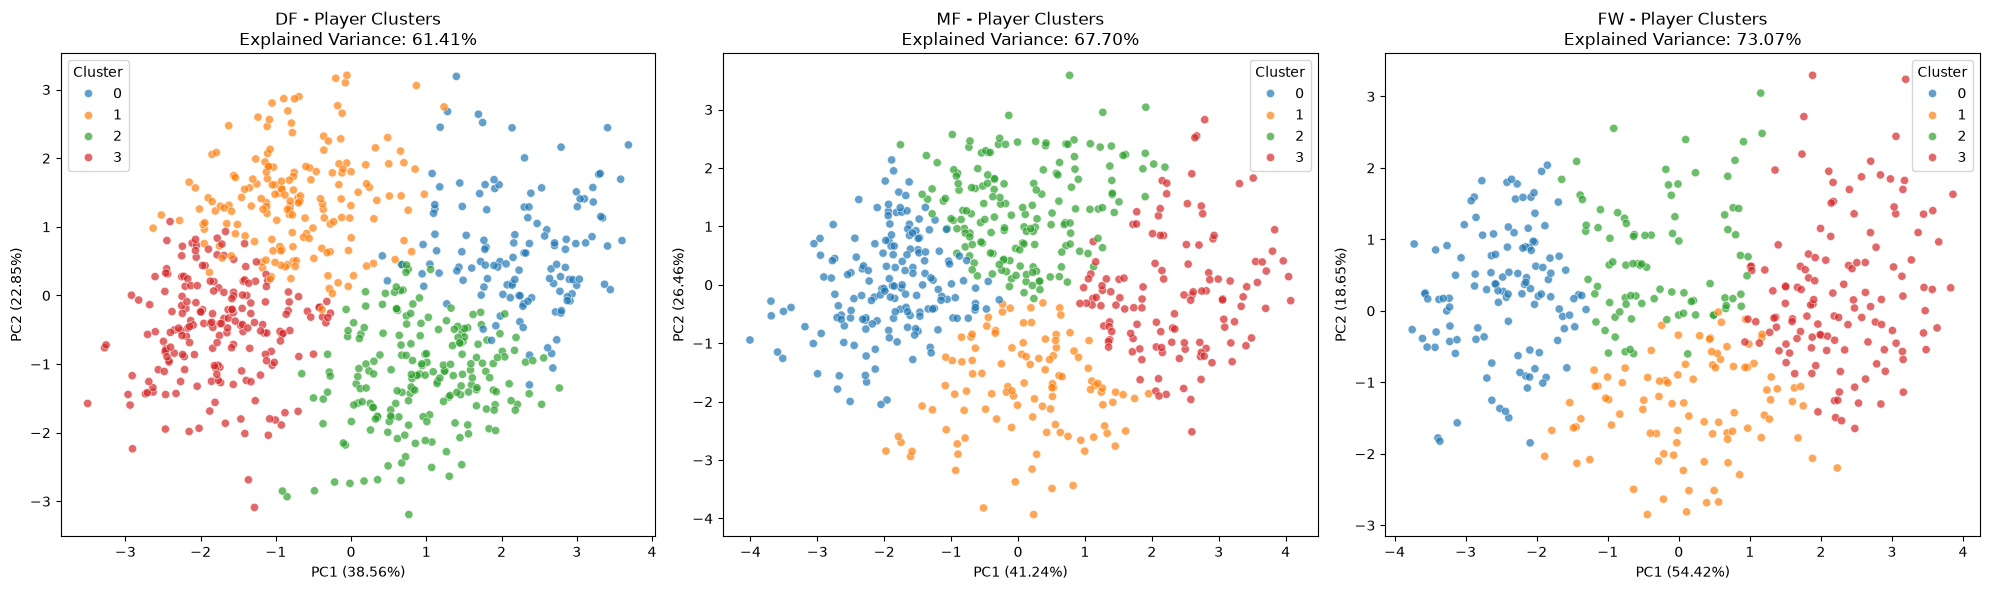

In [30]:
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, position in enumerate(["DF", "MF", "FW"]):

    plot_data = df_pca[df_pca["Pos"] == position]

    sns.scatterplot(
        data=plot_data,
        x="PC1",
        y="PC2",
        hue="PlayingStyle_Cluster",
        palette="tab10",
        alpha=0.7,
        s=35,
        ax=axes[i]
    )

    variance = pca_variance[position]

    axes[i].set_title(
        f"{position} - Player Clusters\n"
        f"Explained Variance: {sum(variance):.2%}"
    )

    axes[i].set_xlabel(f"PC1 ({variance[0]:.2%})")
    axes[i].set_ylabel(f"PC2 ({variance[1]:.2%})")

    axes[i].legend(title="Cluster")

plt.tight_layout()
plt.show()

In [31]:
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save player cluster assignments and PCA coordinates
df_pca.to_csv(
    OUTPUT_DIR / "players_clustered.csv",
    index=False
)

# Save cluster summary
cluster_summary.to_csv(
    OUTPUT_DIR / "cluster_summary.csv"
)

print("Saved files:")
print("1. players_clustered.csv")
print("2. cluster_summary.csv")

Saved files:
1. players_clustered.csv
2. cluster_summary.csv
